# 06 · Diễn giải mô hình

**Mục tiêu.** Trả lời yêu cầu 7 của đề: đặc trưng nào chi phối mô hình, và điều đó có hợp lý về mặt vận hành chuỗi cung ứng không. Dùng bốn công cụ bổ sung cho nhau:

| Công cụ | Trả lời câu hỏi | Áp dụng cho |
|---|---|---|
| Permutation importance | Mô hình **dựa vào** biến nào nhiều nhất (điểm giảm bao nhiêu nếu xáo trộn biến đó) | Cả 5 mô hình |
| Partial dependence (PDP) và ICE | Khi một biến tăng, rủi ro dự báo tăng hay giảm, theo dạng nào | Mô hình chính (Random Forest) |
| Cây quyết định độ sâu 3 | Các luật "nếu… thì…" mà quản đốc đọc được | Cây quyết định (đơn giản hoá) |
| Hệ số logistic | Chiều tác động của từng biến khi các biến khác giữ nguyên | Hồi quy logistic |

**Hai lưu ý đọc trước:**
1. Đây là quan hệ **dự báo**, không phải nhân quả. "Tổ có `smv` thấp dễ trượt" không có nghĩa là tăng `smv` sẽ giảm trượt.
2. Bốn biến `department`, `no_of_workers`, `smv` và `wip` **cùng mang thông tin "bộ phận nào"** (mục 2). Khi các biến trùng thông tin, mỗi công cụ ở trên đều có thể chia công lao cho chúng theo cách khác nhau, nên không được đọc từng biến một cách tách rời.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # chạy được từ notebooks/ hoặc từ gốc repo
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
warnings.filterwarnings("ignore", category=FutureWarning)

from config import DATA_FILE, SEED
import plots as P

import features as F
import splits as S
import evaluate as E
import pipeline as PL
import interpret as I

df = F.build_dataset(DATA_FILE)
train, test = S.split_train_test(df)
cv = S.RollingOriginByDate(n_blocks=6)
sel = E.select_models(train, "A", cv)        # khoảng 40 giây
summ = E.summarize_folds(sel["folds"])
chosen = summ.sort_values("average_precision_mean", ascending=False).model.iloc[0]     # PR-AUC CV cao nhất
print("Mô hình chính (PR-AUC CV cao nhất, kịch bản A):", chosen)

Mô hình chính (PR-AUC CV cao nhất, kịch bản A): RandomForest


## 1. Fit lại trên toàn bộ train
Mỗi mô hình được huấn luyện lại trên toàn bộ train với siêu tham số đã chọn ở `04_models`, giống hệt mô hình dùng để đánh giá test.

In [2]:
est = {m: E.fit_final_and_predict_test(m, "A", sel["best"][m], train, test)[0] for m in PL.MODEL_NAMES}

## 2. Các biến cùng mang thông tin bộ phận
**Vì sao phải kiểm tra trước.** EDA cho thấy finishing trượt gấp 2,4 lần sewing, nên "bộ phận" là tín hiệu mạnh nhất. Nhưng tổ finishing cũng là tổ **ít người**, làm mã hàng **`smv` thấp** và **không có `wip`**. Nếu một biến gần như xác định được bộ phận, mô hình có thể dùng nó thay cho `department`, và khi đó độ quan trọng của biến ấy thực chất là độ quan trọng của bộ phận.

In [3]:
chk = {
    "no_of_workers <= 10": train["no_of_workers"] <= 10,
    "smv <= 4.5": train["smv"] <= 4.5,
    "wip thiếu (điền 0)": train["wip"].isna(),
}
pd.concat({k: pd.crosstab(train["department"], v) for k, v in chk.items()}, axis=1)

no_of_workers <= 10       smv <= 4.5       wip thiếu (điền 0)      
no_of_workers               False True       False True               False True 
department                                                                       
finishing                     106   285         33   358                  0   391
sewing                        552     0        552     0                552     0

**Nhận xét.**
- Trong train, **mọi** dòng có ≤ 10 công nhân đều là finishing (285 dòng), sewing không có dòng nào. Tương tự, mọi dòng có `smv` ≤ 4,5 đều là finishing (358 dòng). `wip` thì thiếu ở đúng 100% dòng finishing và không thiếu ở dòng sewing nào.
- Nghĩa là `no_of_workers`, `smv` và `wip` mỗi biến đều gần như **xác định được bộ phận**. Mô hình không cần `department` cũng biết dòng đó là finishing hay sewing.
- Hệ quả khi đọc các mục sau: một biến trong nhóm này có độ quan trọng cao chủ yếu vì nó **thay cho bộ phận**. Ví dụ, "`no_of_workers` quan trọng nhất" nên hiểu là "**tổ finishing** rủi ro cao", không phải "tổ ít người thì dễ trượt". Từ dữ liệu này không tách được hai cách hiểu đó, vì không có tổ finishing đông người hay tổ sewing ít người.

## 3. Permutation importance trên test
**Cách làm.** Xáo trộn ngẫu nhiên một cột (giữ nguyên các cột khác) rồi đo PR-AUC giảm bao nhiêu; lặp 30 lần lấy trung bình. Một biến quan trọng thì xáo trộn nó làm điểm giảm nhiều. Cách này áp dụng được cho mọi mô hình, kể cả SVM và MLP.

**Hạn chế cần biết.**
- Tính trên test (254 dòng): số dòng ít nên kết quả nhiễu; giá trị gần 0 hoặc âm nhỏ là nhiễu, không phải "biến có hại".
- Khi hai biến trùng thông tin, xáo trộn một biến thì biến kia bù vào, nên **cả hai đều trông kém quan trọng** hơn thực tế.
- Xáo trộn `wip` gán giá trị của sewing cho dòng finishing và ngược lại, nên phá luôn thông tin bộ phận ẩn trong `wip`.

Giảm PR-AUC trung bình khi xáo trộn (cả 5 mô hình):


model,Cây quyết định,Hồi quy logistic,Mạng nơ-ron (MLP),Random Forest,SVM (RBF)
feature,,,,,
day,0.000,-0.003,0.001,-0.002,-0.001
department,0.000,0.038,0.030,0.010,-0.003
is_first_obs,0.000,0.000,0.000,0.000,0.000
lag1_gap,0.009,0.029,0.067,0.014,-0.006
lag1_miss,0.000,0.007,0.015,0.009,-0.005
no_of_workers,0.222,0.200,0.001,0.120,0.003
roll5_gap_mean,-0.016,0.001,0.053,0.010,-0.013
roll5_miss_rate,0.094,0.083,-0.005,0.031,0.017
smv,0.101,0.026,-0.006,0.068,-0.009


Random Forest: trung bình ± độ lệch chuẩn qua 30 lần xáo trộn


,feature,mean,std
0,no_of_workers,0.120,0.032
1,smv,0.068,0.021
2,roll5_miss_rate,0.031,0.018
3,wip,0.023,0.012
4,lag1_gap,0.014,0.017
5,department,0.010,0.009
6,roll5_gap_mean,0.010,0.019
7,lag1_miss,0.009,0.011
8,targeted_productivity,0.005,0.005
9,team,0.005,0.008


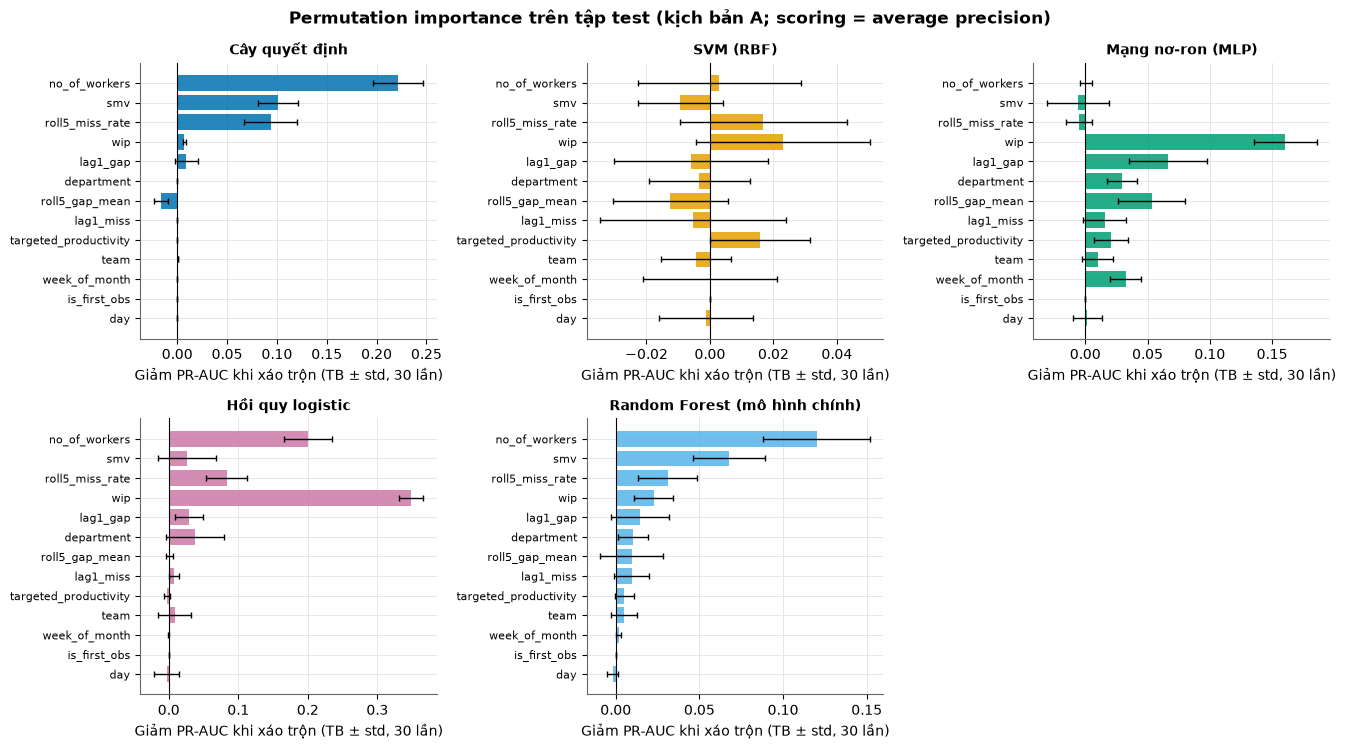

In [4]:
pi = I.permutation_importance_table(est, test, "A", n_repeats=30)
print("Giảm PR-AUC trung bình khi xáo trộn (cả 5 mô hình):")
display(pi.pivot(index="feature", columns="model", values="mean").rename(columns=PL.MODEL_LABELS).round(3))
print(f"{PL.MODEL_LABELS[chosen]}: trung bình ± độ lệch chuẩn qua 30 lần xáo trộn")
display(pi[pi.model == chosen].sort_values("mean", ascending=False)[["feature", "mean", "std"]].round(3).reset_index(drop=True))
fig = P.plot_perm_importance(pi, chosen); plt.show()

**Nhận xét.**
- **Random Forest** dựa nhiều nhất vào `no_of_workers` (giảm PR-AUC 0,120 ± 0,032) và `smv` (0,068 ± 0,021), tức hai biến thay cho bộ phận (mục 2); sau đó là `roll5_miss_rate` (0,031) và `wip` (0,023). Các biến còn lại có độ lệch chuẩn xấp xỉ hoặc lớn hơn trung bình, nên không phân biệt được với 0.
- **Các mô hình chọn "đại diện bộ phận" khác nhau:** cây quyết định chọn `no_of_workers` (0,222), Logistic và MLP chọn `wip` (0,349 và 0,161). Đó là cùng một thông tin được mỗi mô hình lấy qua một cửa khác nhau, không phải mỗi mô hình thấy một quy luật khác nhau.
- **SVM** có độ quan trọng gần 0 với mọi biến (cao nhất 0,023), dù PR-AUC test vẫn 0,546. Đây đúng là hiệu ứng của biến trùng thông tin: xáo trộn một đại diện bộ phận thì các đại diện kia bù vào.
- **Điểm nhất quán giữa các mô hình là lịch sử gần đây:** mô hình nào cũng có ít nhất một đặc trưng trễ (`roll5_miss_rate`, `lag1_gap` hoặc `roll5_gap_mean`) trong nhóm đầu.
- `day`, `team`, `week_of_month`, `targeted_productivity` gần như không đóng góp. `is_first_obs` bằng đúng 0 vì test không có dòng nào chưa có lịch sử, nên xáo trộn cột này không thay đổi gì.

## 4. Partial dependence và ICE
**Cách đọc.** Đường đậm (PDP) là rủi ro dự báo trung bình khi đặt một biến về từng giá trị, giữ nguyên các biến khác của mọi dòng. Các đường mảnh (ICE) là cùng phép thử cho từng dòng riêng lẻ (mẫu 40 dòng); nếu các đường mảnh song song thì tác động của biến khá đồng đều, nếu chúng đi lệch nhau thì có tương tác với biến khác.

Trục tung là **điểm rủi ro thô** của Random Forest (chưa hiệu chỉnh), nên mức tuyệt đối cao hơn xác suất thật; chỉ nên đọc **chiều và hình dạng**. Riêng `wip` chỉ tính trên dòng sewing, vì gán `wip` cho finishing là phi thực tế.

Đặc trưng hàng đầu của RandomForest : ['no_of_workers', 'smv', 'roll5_miss_rate', 'wip']


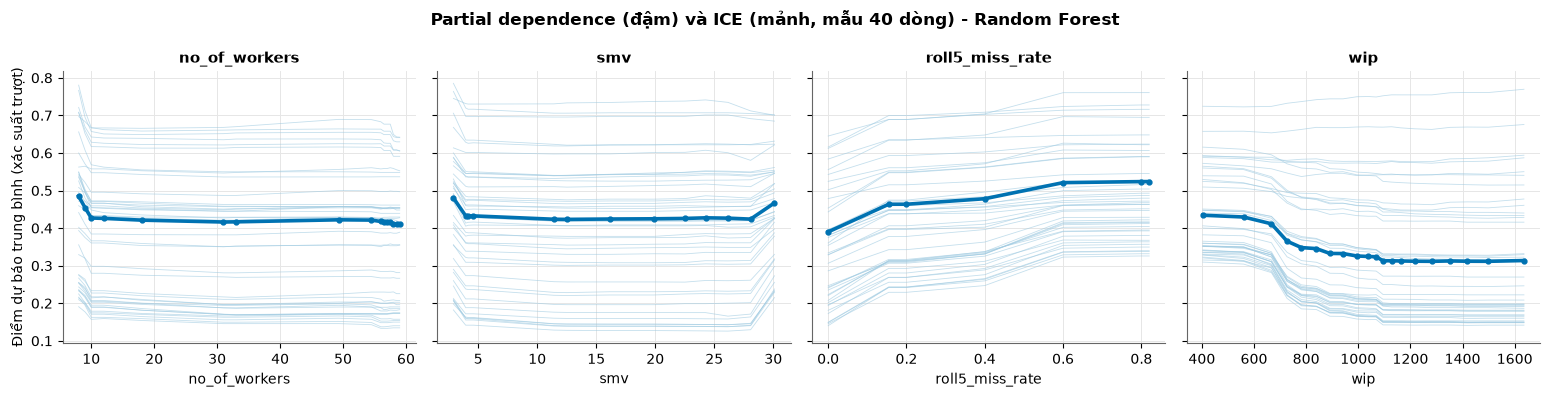

In [5]:
top = I.top_features(pi, chosen, 4)
print("Đặc trưng hàng đầu của", chosen, ":", top)
pdp = I.pdp_table(est[chosen], train[PL.SCENARIOS["A"].columns], top)
ylabel = "Điểm dự báo trung bình (xác suất trượt)" if chosen != "SVM_RBF" else "Điểm dự báo trung bình (decision function)"
fig = P.plot_pdp(pdp, top, P.SHORT[chosen], ylabel); plt.show()

**Nhận xét.**
- **`no_of_workers`:** rủi ro cao ở mức 8–9 công nhân (khoảng 0,48) rồi giảm xuống khoảng 0,43 từ 10 công nhân trở lên và **phẳng hẳn** sau đó. Một bậc thang duy nhất đúng tại ranh giới finishing/sewing: biến này đang đóng vai "bộ phận", không có quan hệ "càng đông càng an toàn".
- **`smv`:** tương tự, rủi ro cao ở `smv` rất thấp (mã hàng của finishing), phẳng ở giữa, chỉ nhích lên ở `smv` khoảng 30 (mã hàng rất phức tạp; khớp với luật "`smv` > 30,2" của cây, nhưng chỉ có 14 dòng).
- **`roll5_miss_rate`:** tăng đều từ khoảng 0,39 (không trượt lần nào trong 5 lần trước) lên khoảng 0,52 (trượt từ 3/5 lần trở lên). Đây là quan hệ rõ nhất và đúng chiều với lập luận "vấn đề của tổ kéo dài sang ngày sau".
- **`wip` (chỉ sewing):** rủi ro giảm từ khoảng 0,43 khi `wip` dưới 650 xuống khoảng 0,31 khi `wip` trên khoảng 1.100, rồi phẳng. Tổ có đệm bán thành phẩm lớn ít bị trượt.
- Các đường ICE gần như song song: tác động của mỗi biến khá giống nhau giữa các dòng, khác nhau chủ yếu ở mức nền (do các biến khác).

## 5. Cây quyết định độ sâu ≤ 3 (ngưỡng theo đơn vị gốc)
**Vì sao.** Random Forest có 300 cây nên không đọc trực tiếp được. Một cây nông với cùng siêu tham số (trừ độ sâu) cho các luật mà quản đốc đọc được ngay, với ngưỡng theo đơn vị gốc (cây không cần chuẩn hoá nên được fit lại trên dữ liệu chưa chuẩn hoá; ô dưới kiểm tra dự báo trùng 100% với bản chuẩn hoá).

Tỷ lệ dự báo trùng với cây cùng tham số trên dữ liệu chuẩn hoá: 1.0


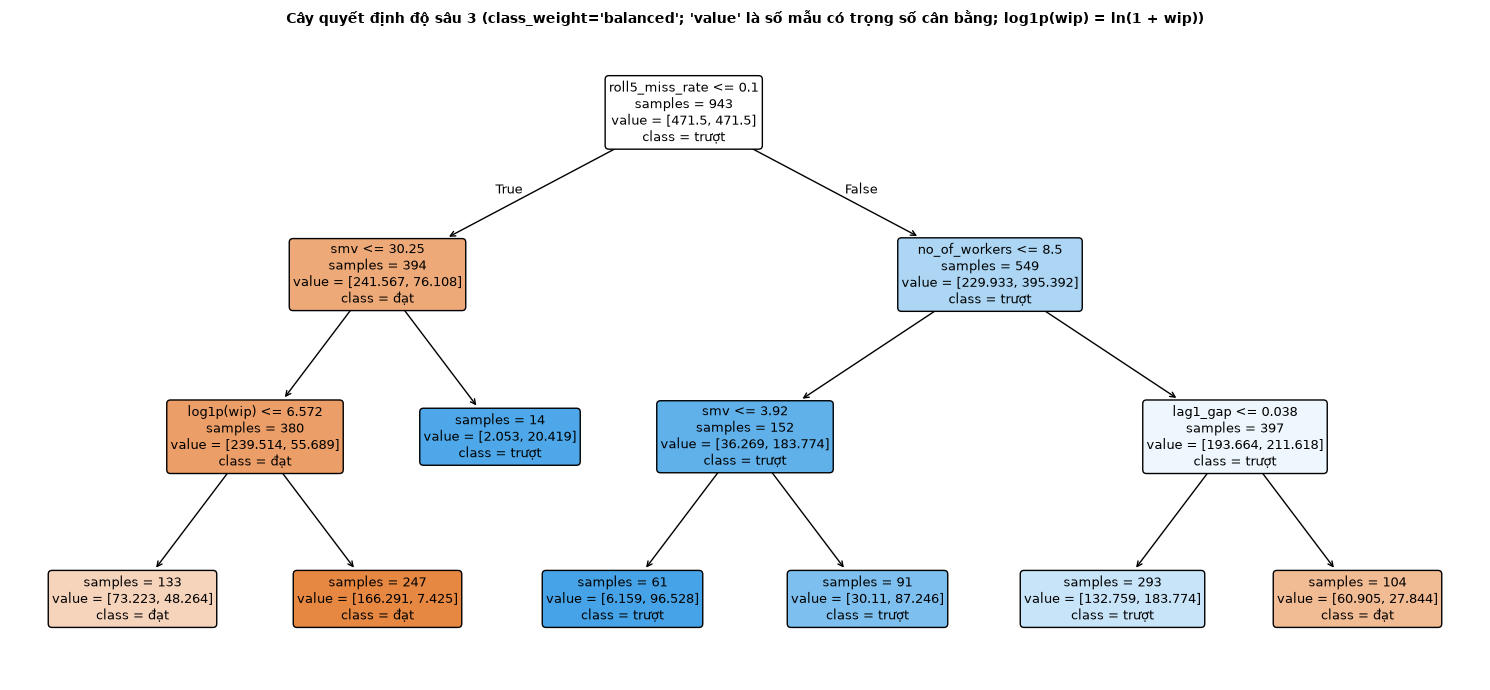

,leaf,rule,n_train,n_miss,miss_rate_train,p_miss_weighted
0,8,roll5_miss_rate > 0.1 AND no_of_workers <= 8.5 AND smv <= 3.92,61,52,0.852,0.940
1,5,roll5_miss_rate <= 0.1 AND smv > 30.2,14,11,0.786,0.909
2,9,roll5_miss_rate > 0.1 AND no_of_workers <= 8.5 AND smv > 3.92,91,47,0.516,0.743
3,11,roll5_miss_rate > 0.1 AND no_of_workers > 8.5 AND lag1_gap <= 0.0376,293,99,0.338,0.581
4,3,roll5_miss_rate <= 0.1 AND smv <= 30.2 AND wip <= 714,133,26,0.195,0.397
5,12,roll5_miss_rate > 0.1 AND no_of_workers > 8.5 AND lag1_gap > 0.0376,104,15,0.144,0.314
6,4,roll5_miss_rate <= 0.1 AND smv <= 30.2 AND wip > 714,247,4,0.016,0.043


In [6]:
prep, tree, agree = I.fit_interpretable_tree(train, sel["best"]["DecisionTree"], "A", max_depth=3)
print("Tỷ lệ dự báo trùng với cây cùng tham số trên dữ liệu chuẩn hoá:", agree)
fig = I.plot_tree_figure(prep, tree); plt.show()
I.tree_leaf_table(prep, tree, train, "A").round(3)

**Nhận xét.**
- Lần tách **đầu tiên** là theo lịch sử (`roll5_miss_rate` > 0,1, tức đã trượt ít nhất 1 trong 5 lần trước), sau đó mới tới quy mô tổ và mã hàng. Lịch sử gần đây là tín hiệu mạnh nhất mà cây tìm được.
- Nên đọc cột `miss_rate_train` (tỷ lệ trượt thật trong lá). Cột `p_miss_weighted` là xác suất của cây với trọng số cân bằng lớp, nên cao hơn thực tế.
- **Nhóm rủi ro cao nhất:** vừa trượt gần đây, ≤ 8 công nhân, `smv` ≤ 3,92, tức **tổ finishing nhỏ đang có vấn đề**: 61 dòng, trượt 85%.
- **Nhóm an toàn nhất:** không trượt gần đây, `smv` ≤ 30,2 và `wip` > 714, tức **tổ sewing ổn định có đệm bán thành phẩm**: 247 dòng, chỉ trượt 1,6%.
- Nhóm lớn nhất (293 dòng, trượt 34%): đã trượt gần đây, tổ đông người, và lần trước chưa vượt định mức quá 3,8 điểm phần trăm.
- Luật "không trượt gần đây và `smv` > 30,2" có tỷ lệ trượt 79% nhưng chỉ dựa trên 14 dòng, không đáng tin.

## 6. Hệ số logistic
**Cách đọc và cảnh báo.** Mỗi hệ số là thay đổi log-odds của rủi ro khi biến tăng một độ lệch chuẩn (với biến số) hoặc khi dòng thuộc hạng mục đó (với one-hot), giữ nguyên các biến khác. Ở mô hình này, hệ số **không đọc riêng lẻ được** vì ba lý do:
1. `department`, `log1p(wip)`, `no_of_workers`, `smv` trùng thông tin bộ phận (mục 2). "Giữ nguyên các biến khác" là một tình huống không có thật: không có tổ finishing nào có `wip` lớn hay 57 công nhân.
2. One-hot giữ đủ mọi hạng mục, nên `department_finishing` và `department_sewing` luôn cộng lại bằng 1; chỉ **hiệu** giữa chúng có nghĩa.
3. Siêu tham số chọn được là `C = 100`, gần như không phạt, nên khi các biến trùng thông tin thì hệ số có thể lớn và đổi dấu tuỳ ý.

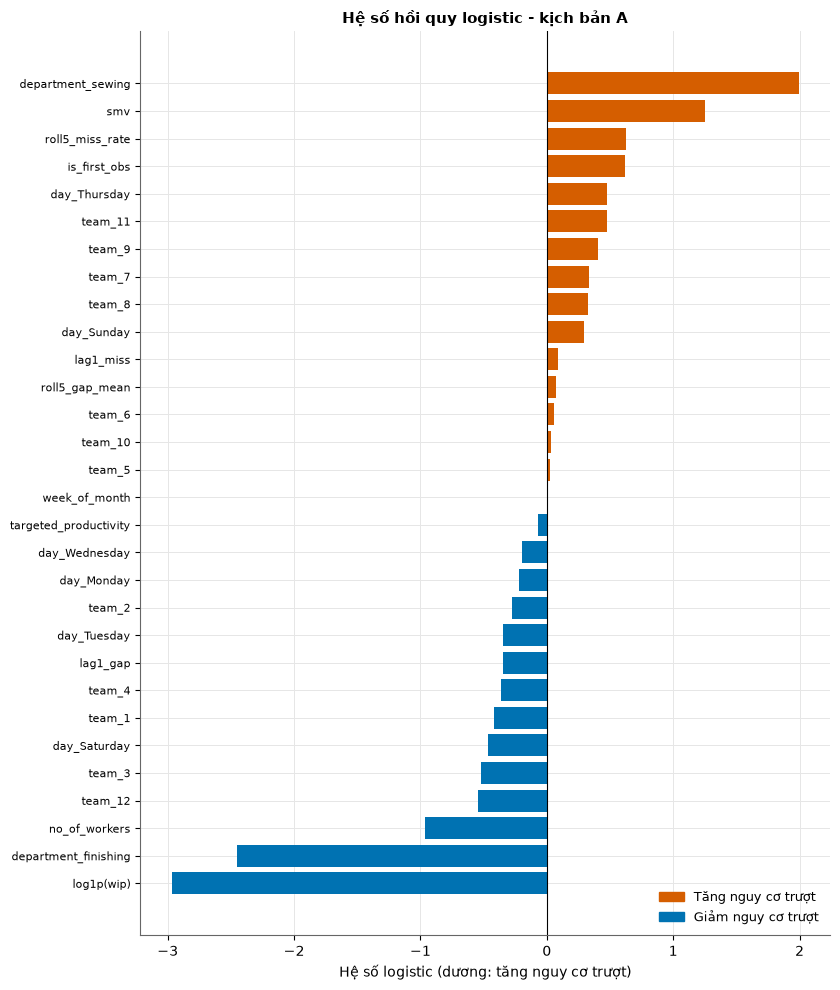

,feature,coef,abs_coef
0,log1p(wip),-2.969,2.969
1,department_finishing,-2.451,2.451
2,department_sewing,1.993,1.993
3,smv,1.250,1.250
4,no_of_workers,-0.962,0.962
5,roll5_miss_rate,0.628,0.628
6,is_first_obs,0.619,0.619
7,team_12,-0.541,0.541
8,team_3,-0.518,0.518
9,day_Thursday,0.473,0.473


In [7]:
coef = I.logistic_coefficients(est["Logistic"])
fig = P.plot_coefficients(coef); plt.show()
coef.round(3).head(10)

**Nhận xét.**
- **Hệ số của `department` ngược trực giác:** `department_finishing` = −2,45 và `department_sewing` = +1,99, như thể finishing *an toàn hơn*, trong khi thực tế finishing trượt gấp 2,4 lần.
- Nguyên nhân là các biến đại diện bộ phận đã "hút" phần lớn hiệu ứng. Ví dụ với `log1p(wip)` (hệ số −2,97): finishing có `wip = 0`, sau chuẩn hoá thành khoảng −1,17, nên riêng biến này **cộng** khoảng +3,5 vào log-odds của mọi dòng finishing. Cộng gộp các đóng góp của `department`, `wip`, `no_of_workers` và `smv` cho một tổ finishing điển hình so với một tổ sewing điển hình, log-odds của finishing vẫn cao hơn khoảng 1,6, tức mô hình **vẫn đánh giá finishing rủi ro hơn**, đúng với dữ liệu. Chỉ là phần đó bị chia ra nhiều hệ số với dấu trái ngược nhau.
- Những hệ số **đọc được** (không thuộc nhóm đại diện bộ phận):
  - `roll5_miss_rate` +0,63: trượt nhiều gần đây thì rủi ro cao hơn, cùng chiều với PDP và cây.
  - `team_12` −0,54 và `team_3` −0,52: hai tổ có tỷ lệ trượt thấp nhất trong EDA (16% và 12%).
  - `is_first_obs` +0,62: dòng chưa có lịch sử bị coi là rủi ro hơn; ảnh hưởng ít vì chỉ có 24 dòng như vậy, đều ở train.
- `day_Thursday` +0,47 chưa có lý giải vận hành rõ, có thể là nhiễu.

## 7. Có hợp lý về vận hành không?

| Mô hình thấy | Có hợp lý không | Lưu ý |
|---|---|---|
| Tổ finishing (ít người, `smv` thấp, không có `wip`) rủi ro cao | **Có.** Finishing là khâu cuối, phụ thuộc vào đầu ra của sewing; tổ nhỏ khó bù khi thiếu người hoặc thiếu hàng | Không tách được "do bộ phận" hay "do quy mô tổ"; không nên kết luận "thêm người cho tổ sẽ giảm trượt" |
| Tổ vừa trượt gần đây dễ trượt tiếp | **Có.** Vấn đề như mã hàng khó, thiếu người, máy hỏng thường kéo dài vài ngày | Nhất quán ở cả 5 mô hình, PDP và cây; đây là thông tin mà B1 cũng dùng |
| Tổ sewing có `wip` lớn ít trượt | **Có.** Đệm bán thành phẩm giúp tổ không bị "đói việc" khi khâu trước chậm | Chỉ đo được ở sewing |
| Mã hàng rất phức tạp (`smv` > 30) rủi ro cao | Có thể | Chỉ 14 dòng |
| Định mức, thứ trong tuần, tuần trong tháng gần như không giúp dự báo | Đáng chú ý: định mức cao không làm tổ dễ trượt hơn | – |

**Không trả lời được:** thưởng (`incentive`) và tăng ca (`over_time`) có làm thay đổi năng suất không, vì kịch bản A đã loại hai biến này để tránh rò rỉ. Mọi quan hệ ở đây là **dự báo**, không phải nhân quả.

**Hệ quả cho khuyến nghị:** tín hiệu lớn nhất của mô hình là "bộ phận", mà quy tắc B2 "mọi tổ finishing" đã nắm được. Phần mô hình thêm vào chủ yếu là lịch sử gần đây và `wip`. Điều này giải thích vì sao trên test B2 gần ngang mô hình (`05_cost`), và vì sao lý do trên phiếu cảnh báo hay ghi "số công nhân = 8": thực chất đó là "đây là tổ finishing".